In [1]:
import h5pyd
import h5py
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import haversine
from haversine import haversine, Unit
import numpy as np
from datetime import datetime
from matplotlib.patches import Rectangle

In [2]:
sites = pd.read_csv('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Data/MasterSiteList_FollowupPaper.csv')
sites = sites.iloc[0:15,0:8]

In [3]:
%%time
#12 min
#Read in data, count up number of times steps and coords and then limit to 2013-2023 data
temp = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles_NO3/surface_NO3_all.csv")
#temp_east is 10,733,967 rows long
temp_east = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles_NO3/surface_NO3_east_all.csv")
temp = pd.concat([temp,temp_east])
temp = temp.dropna()
print("Number of time steps is", temp.ocean_time.nunique())
print("Lat/lon combos is", len(temp[['lon_rho','lat_rho']].drop_duplicates()))
#drop 2024 values and reset index
temp.ocean_time = pd.to_datetime(temp.ocean_time)
temp = temp.loc[temp.ocean_time < "2023-12-31"].reset_index()

Number of time steps is 4383
Lat/lon combos is 48278
CPU times: total: 10min 19s
Wall time: 16min 39s


In [4]:
%%time
#Ok calculating the haversine distances over this many columns is not happening....

lat = sites.SiteLatitude[0]
lon = sites.SiteLongitude[0]
site = (lat, lon)
site_rounded = (round(lat,2), round(lon, 2))
#temp["lat_rounded"] = round(temp.lat_rho,2)
#temp["lon_rounded"] = round(temp.lon_rho,2)
temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
def hav_dist(row):
    site2 = (row["lat_rho"],row["lon_rho"])
    return haversine(site,site2)
dist = temp_sub.apply(hav_dist, axis = 1)
index1 = dist[dist == dist.min()].index
temp_forsites = temp.iloc[index1.values[:],]

for i in range(1,len(sites)): 
    #print(i, "has the latitude", sites.SiteLatitude[i])
    site = (sites.SiteLatitude[i], sites.SiteLongitude[i])
    temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
    dist = temp_sub.apply(hav_dist, axis = 1)
    index1 = dist[dist == dist.min()].index
    closest = temp.iloc[index1.values[:],]
    print(i)
    print(closest.iloc[1,6])
    temp_forsites = pd.concat([temp_forsites,closest])
    print(i," is finished, hooray!")

1
45.21331748549788
1  is finished, hooray!
2
44.78383099999047
2  is finished, hooray!
3
44.74972204231666
3  is finished, hooray!
4
43.342748340363855
4  is finished, hooray!
5
43.32052277193761
5  is finished, hooray!
6
43.29821697682596
6  is finished, hooray!
7
42.83479975382984
7  is finished, hooray!
8
42.78659473126096
8  is finished, hooray!
9
42.73804107337505
9  is finished, hooray!
10
42.70139552190807
10  is finished, hooray!
11
42.66455137467071
11  is finished, hooray!
12
42.43925529923458
12  is finished, hooray!
13
42.06055447045627
13  is finished, hooray!
14
42.03370062156226
14  is finished, hooray!
CPU times: total: 5min 16s
Wall time: 5min 22s


In [5]:
temp_forsites

,index,ocean_time,eta_rho,xi_rho,surf_temp,lon_rho,lat_rho
184764617,24453,2013-01-01 12:00:00,326,3,9.590682,-123.981283,45.335118
184767066,59928,2013-01-02 12:00:00,326,3,9.634803,-123.981283,45.335118
184769515,95403,2013-01-03 12:00:00,326,3,9.620764,-123.981283,45.335118
184771964,130878,2013-01-04 12:00:00,326,3,9.619481,-123.981283,45.335118
184774413,166353,2013-01-05 12:00:00,326,3,9.645530,-123.981283,45.335118
...,...,...,...,...,...,...,...
184534321,221973061,2023-12-26 12:00:00,2,76,5.761341,-124.294192,42.033701
184580328,222028402,2023-12-27 12:00:00,2,76,5.844657,-124.294192,42.033701
184626335,222083743,2023-12-28 12:00:00,2,76,6.065484,-124.294192,42.033701
184672342,222139084,2023-12-29 12:00:00,2,76,6.339093,-124.294192,42.033701


C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/LOOK_TempDist_Feb2026.jpg


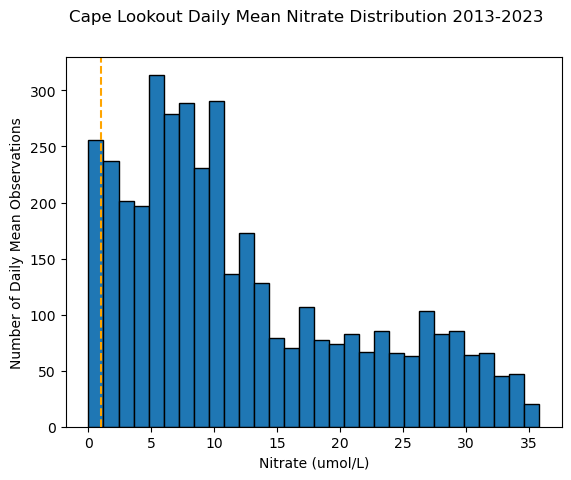

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/PACC_TempDist_Feb2026.jpg


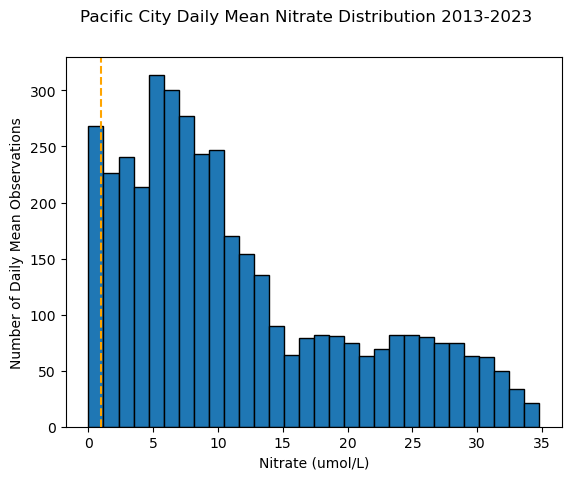

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/FOUL_TempDist_Feb2026.jpg


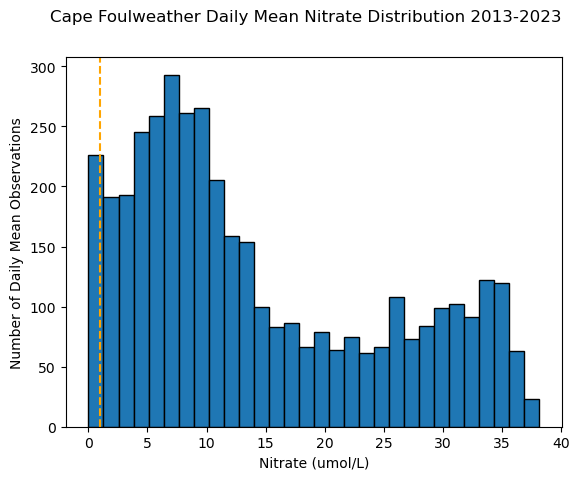

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/OTRK_TempDist_Feb2026.jpg


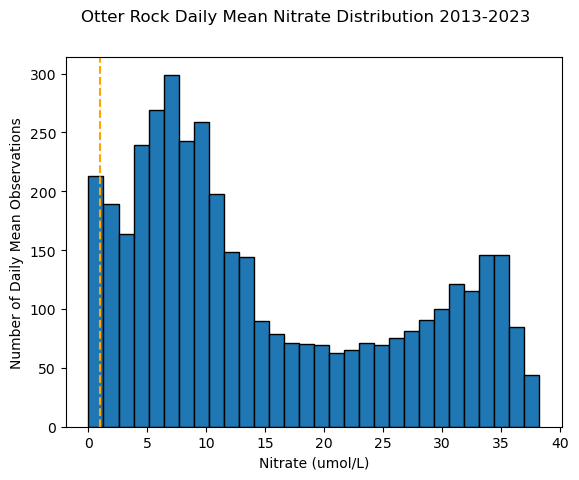

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/GREG_TempDist_Feb2026.jpg


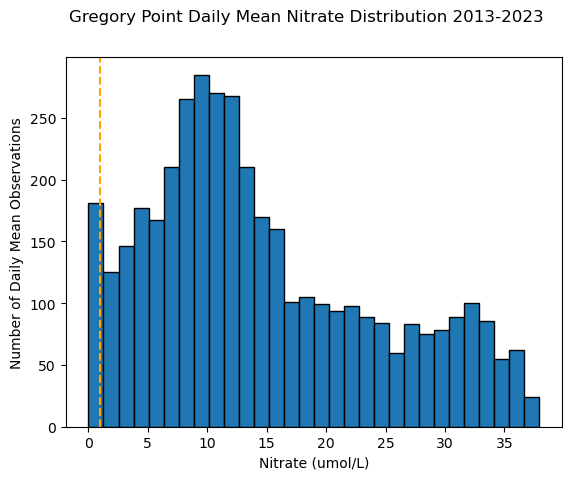

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/SIMP_TempDist_Feb2026.jpg


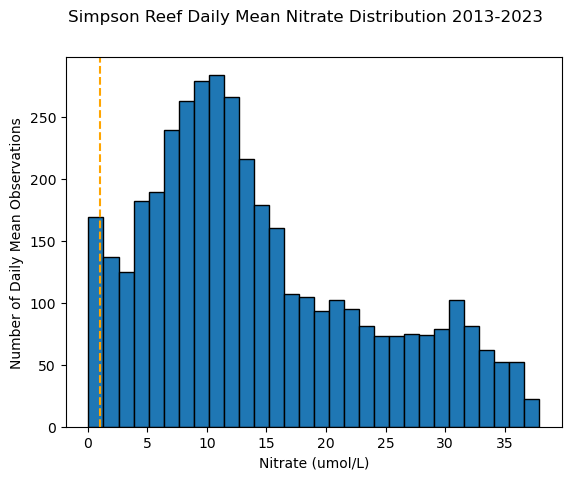

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/DRAK_TempDist_Feb2026.jpg


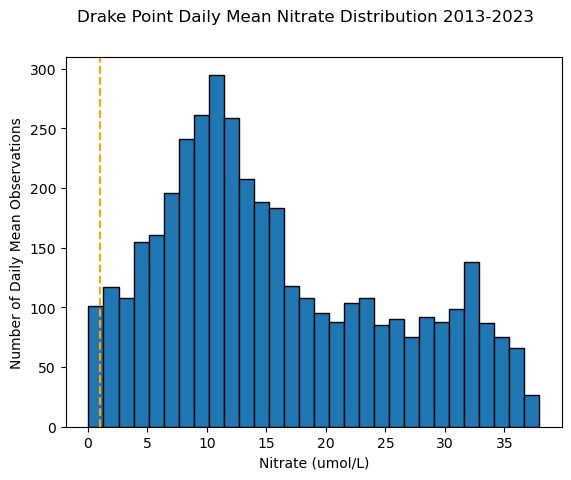

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/BLCO_TempDist_Feb2026.jpg


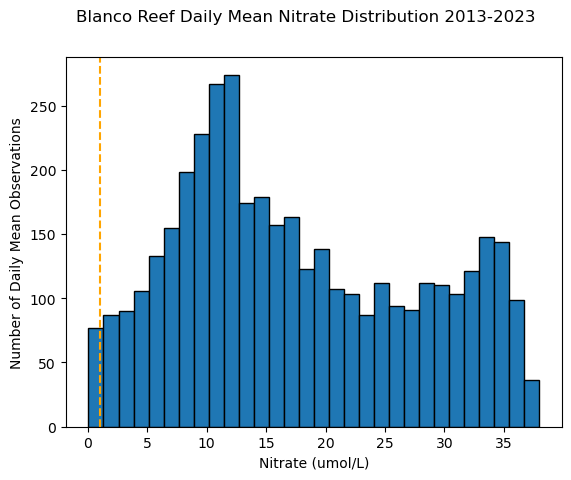

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/ORRF_TempDist_Feb2026.jpg


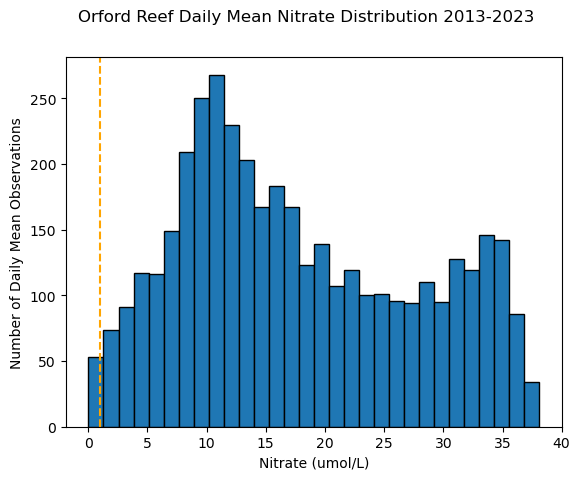

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/ORFH_TempDist_Feb2026.jpg


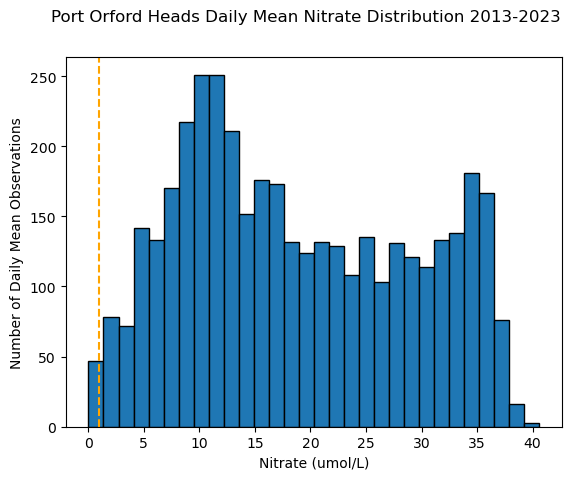

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/RFSH_TempDist_Feb2026.jpg


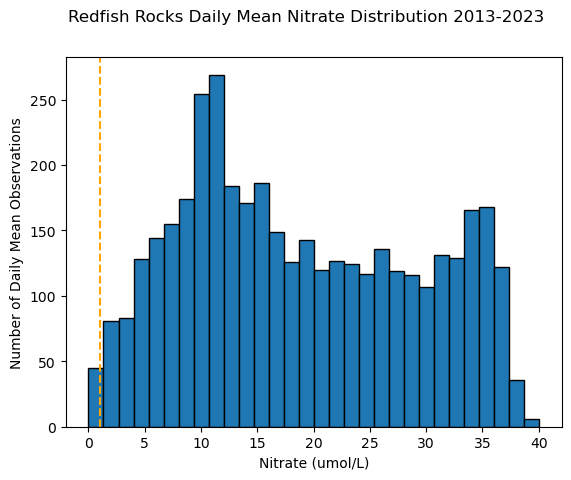

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/HMBG_TempDist_Feb2026.jpg


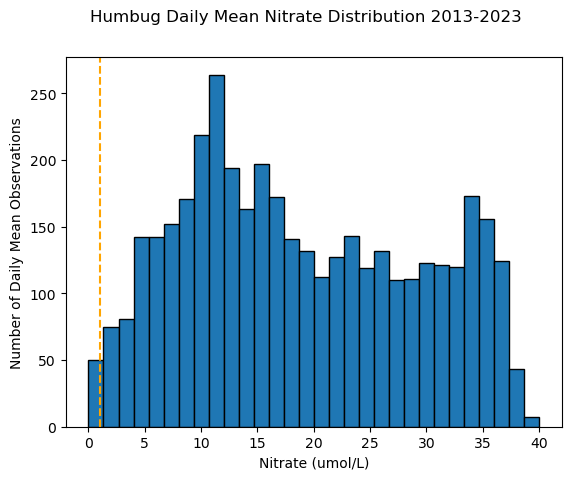

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/ROGU_TempDist_Feb2026.jpg


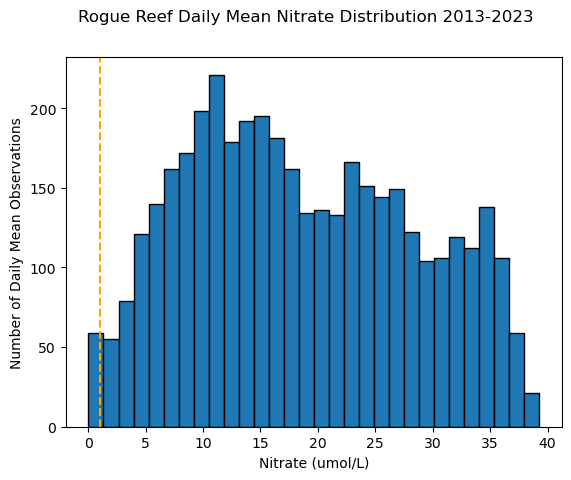

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/HARB_TempDist_Feb2026.jpg


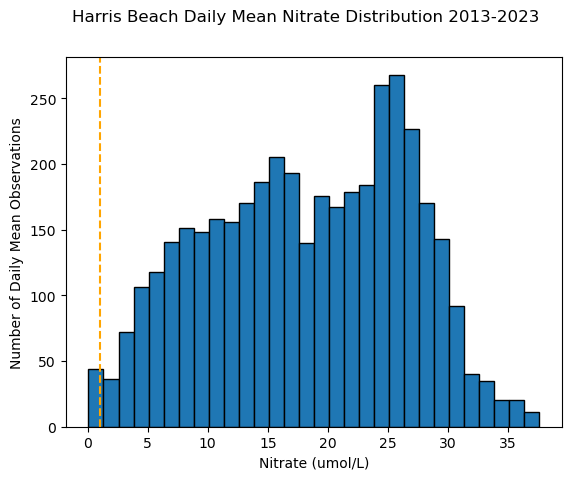

C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/CHET_TempDist_Feb2026.jpg


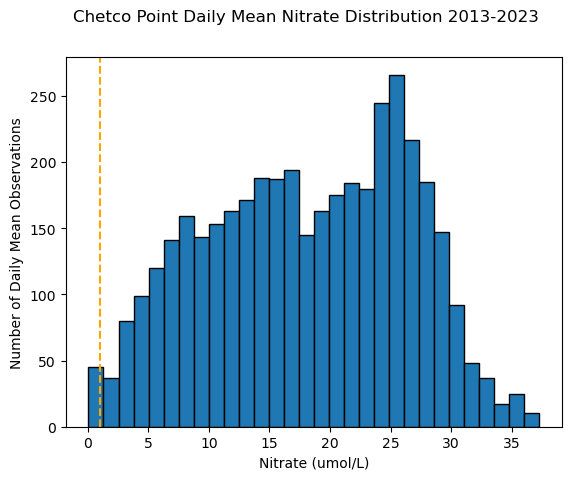

In [9]:
sitecoords = temp_forsites[["lat_rho","lon_rho"]].drop_duplicates()
type(temp_forsites)
for i in [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14]:
    sitedata = temp_forsites.loc[(temp_forsites["lat_rho"] == sitecoords.iloc[i,0]) & (temp_forsites["lon_rho"] == sitecoords.iloc[i,1])].reset_index()
    fig, ax = plt.subplots()
    title = sites.iloc[i,0] + " Daily Mean Nitrate Distribution 2013-2023" 
    fig.suptitle(title)
    ax.hist(sitedata.surf_temp,bins = 30, edgecolor = "black")
    plt.axvline(x=1, color='orange', linestyle='--', label='1 umol/L')
    plt.ylabel("Number of Daily Mean Observations")
    plt.xlabel("Nitrate (umol/L)")
    filename = 'C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/NitrateHistograms/' + sites.iloc[i,1]+  '_TempDist_Feb2026.jpg'
    print(filename)
    plt.savefig(filename)
    plt.show()


In [11]:
#by site, time above 18, 15, 12 and mean temp

def time_below_1(data):
    return len(data.loc[data.surf_temp < 1])/len(data)*100
nitunder1 = temp_forsites.groupby("lat_rho").apply(time_below_1).reset_index()
#and then assign to the matrix
nitunder1_reordered = nitunder1.iloc[::-1].reset_index()
sites["Nit_Under1umol"] = nitunder1_reordered.iloc[:,2]

nitmean = temp_forsites.groupby("lat_rho").surf_temp.mean()
nitmean_reordered = nitmean.iloc[::-1].reset_index()
sites["Nit_Mean"] = nitmean_reordered.iloc[:,1]
sites

sites.to_csv("C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/SummaryStats_NitrateDistributions.csv")

C:\Users\sarah\AppData\Local\Temp\ipykernel_7996\3898738208.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  nitunder1 = temp_forsites.groupby("lat_rho").apply(time_below_1).reset_index()


In [14]:
sites

,Site,SiteCode,Area,AreaCode,Port,SiteLatitude,SiteLongitude,Number2023Trans_Estiamted,Nit_Under1umol,Nit_Mean
0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0,5.702191,12.215722
1,Pacific City,PACC,Cape Lookout,LKOUT,Pacific City,45.212470,-123.985186,12,5.776892,11.560737
2,Cape Foulweather,FOUL,Cape Foulweather,FOULW,Depoe Bay,44.784468,-124.074200,44,4.955179,14.330551
3,Otter Rock,OTRK,Cape Foulweather,FOULW,Depoe Bay,44.746630,-124.072591,52,4.731076,15.126274
4,Gregory Point,GREG,Cape Arago,ARAGO,Coos Bay,43.339313,-124.378642,10,3.635458,14.665780
5,Simpson Reef,SIMP,Cape Arago,ARAGO,Coos Bay,43.315740,-124.404422,16,3.212151,14.368735
6,Drake Point,DRAK,Cape Arago,ARAGO,Coos Bay,43.300839,-124.400720,14,1.917331,15.796427
7,Blanco Reef,BLCO,Cape Blanco,BLANC,Port Orford,42.831791,-124.581814,16,1.245020,17.611699
8,Orford Reef,ORRF,Cape Blanco,BLANC,Port Orford,42.788491,-124.595368,26,1.045817,17.763879
9,Port Orford Heads,ORFH,Cape Blanco,BLANC,Port Orford,42.735759,-124.507747,26,0.921315,18.790775
